# 06.5 Dynamic topic modeling con BERTopic (Híbrido)

Este cuaderno prepara un flujo para modelar temas dinámicos sobre los posteos de Revista Anfibia usando una arquitectura híbrida:
- **Embeddings/Clustering:** Usa el texto original para capturar la sintaxis y semántica.
- **Representación (Palabras clave):** Usa el texto lematizado para evitar redundancia morfológica en español.

In [31]:
# EJECUTAR ESTA CELDA PRIMERO QUE NADA (Y REINICIAR EL KERNEL ANTES SI FALLÓ)
import coverage.types as ct

# Parche de compatibilidad para evitar que Numba/UMAP crasheen
for name, fallback in {
    'Tracer': getattr(ct, 'TTracer', object),
    'TShouldTraceFn': object,
    'TShouldStartContextFn': object,
    'TFileDisposition': object,
}.items():
    if not hasattr(ct, name):
        setattr(ct, name, fallback)

## 1. Configuración del entorno

In [32]:
import os
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from umap import UMAP
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from bertopic.representation import KeyBERTInspired
from bertopic import BERTopic

warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "corpus_anfibia_lematizado.csv"
STOPWORDS_PATH = PROJECT_ROOT / "data" / "processed" / "stopwords_anfibia.txt"

assert DATA_PATH.exists(), f"Falta archivo de entrada: {DATA_PATH.name}"
assert STOPWORDS_PATH.exists(), f"Falta archivo de stopwords: {STOPWORDS_PATH.name}"

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "bertopic_hibrido"
GRAFICOS_DIR = OUTPUT_DIR / "graficos"
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
GRAFICOS_DIR.mkdir(exist_ok=True, parents=True)

## 2. Carga de Corpus y Stopwords
Preparamos los textos, normalizamos categorías y cargamos la lista de stopwords.

In [33]:
MAX_DOCUMENTS = 4000 ## el corpus igual tiene ~3600
USE_COLUMNS = [
    "doc_id", 
    "ID", "source_url", "title_text", "tagline", "autor_names",
    "post_date", "category", "post_tag", "text_type",
    "document_text_original", "document_text_final"
]

df = pd.read_csv(DATA_PATH, usecols=USE_COLUMNS, nrows=MAX_DOCUMENTS)

print(f"Documentos listos: {df.shape[0]}")

# Normalizar categorías vectorizado
def split_categories(val):
    return [p.strip() for p in re.split(r"[;,]", str(val)) if p.strip()]

categories_df = (
    df[["doc_id", "category"]]
    .assign(category_normalized=df["category"].map(split_categories))
    .explode("category_normalized")
    .fillna({"category_normalized": "Sin categoria"})
    [["doc_id", "category_normalized"]]
)

# Textos, fechas y stopwords
docs_naturales = df["document_text_original"].tolist()
docs_lematizados = df["document_text_final"].tolist()
timestamps = pd.to_datetime(df["post_date"].str.split(' ').str[0], format="%Y-%m-%d", errors="coerce")

with open(STOPWORDS_PATH, "r", encoding="utf-8") as f:
    STOPWORDS_LIST = f.read().splitlines()

Documentos listos: 3556


## 3. Entrenamiento Híbrido y Reducción de Outliers (Instancia Única)

1. Calculamos embeddings sobre el texto.
2. Clusterizamos (UMAP + HDBSCAN).
3. Reasignamos las notas outliers (-1).
4. Extraemos las palabras clave con el texto lematizado y las stopwords.

In [34]:
from hdbscan import HDBSCAN

print("1. Calculando embeddings originales...")
embedding_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
embeddings_naturales = embedding_model.encode(docs_naturales, show_progress_bar=True)

print("\n2. Configurando componentes...")
vectorizer_model = CountVectorizer(stop_words=STOPWORDS_LIST, min_df=3)
representation_model = KeyBERTInspired()
umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=42)

#
hdbscan_model = HDBSCAN(
    min_cluster_size=10,       
    min_samples=3,            
    metric='euclidean',
    cluster_selection_method='eom',
    prediction_data=True
)

print("\n3. Entrenando modelo base...")
topic_model = BERTopic(
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,      
    embedding_model=embedding_model,
    language="spanish",
    calculate_probabilities=True,
    # min_topic_size ya no hace falta porque lo maneja hdbscan_model
    nr_topics=None,
    representation_model=representation_model,
    vectorizer_model=vectorizer_model,
)

topics_base, probs = topic_model.fit_transform(docs_lematizados, embeddings=embeddings_naturales)


######################### 

# print("\n3. Reasignando notas outliers (-1)...")
# topics_reducidos = topic_model.reduce_outliers(
#     docs_lematizados,
#     topics_base,
#     strategy="embeddings",
#     embeddings=embeddings_naturales
# )

# print("\n4. Recalibrando palabras clave lematizadas de los tópicos (c-TF-IDF)...")
# # Hay que pasarle el vectorizador de nuevo sí o sí
# topic_model.update_topics(
#     docs_lematizados, 
#     topics=topics_reducidos,
#     vectorizer_model=vectorizer_model,
#     representation_model=representation_model
# )
#topics = topics_reducidos

print("\nModelo optimizado y guardado exitosamente.")

1. Calculando embeddings originales...


Batches: 100%|██████████| 112/112 [01:34<00:00,  1.19it/s]



2. Configurando componentes...

3. Entrenando modelo base...

Modelo optimizado y guardado exitosamente.


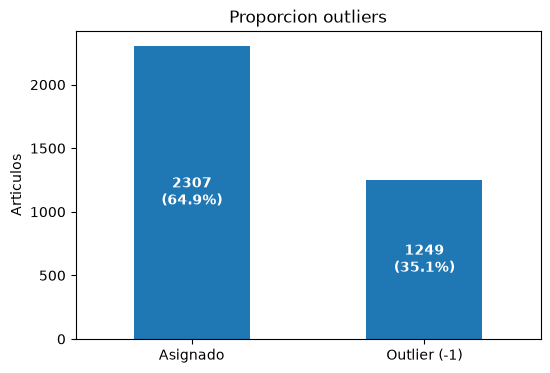

In [35]:
topicos = topics_base

import pandas as pd

counts = pd.Series(["Outlier (-1)" if t == -1 else "Asignado" for t in topicos]).value_counts()

ax = counts.plot(kind="bar", rot=0,figsize=(6, 4))
plt.title("Proporcion outliers")
plt.ylabel("Articulos")

for i, val in enumerate(counts):
    ax.text(i, val / 2, f"{val}\n({val/len(topicos):.1%})", ha="center", va="center", color="white", fontweight="bold")
plt.show()

In [36]:
conteo = pd.Series(topicos).value_counts().sort_index()
print(conteo)

-1     1249
 0      140
 1      134
 2      119
 3      115
       ... 
 75      10
 76      10
 77      10
 78      10
 79      10
Name: count, Length: 81, dtype: int64


In [37]:
import math
def topicos_palabras(topic_model, df, topicos, ruta_html=None):
    df['topic'] = topicos
    total = len(topic_model.get_topic_info().query("Topic != -1"))
    
    fig = topic_model.visualize_barchart(
        top_n_topics=total, 
        n_words=8, 
        title="<b>Palabras representativas (Híbrido)</b>"
    )
    
    colors = px.colors.qualitative.G10
    for i, trace in enumerate(fig.data):
        trace.marker.color = colors[i % len(colors)]
        
    fig.update_traces(hovertemplate="<b>Término:</b> %{y}<br><b>Relevancia:</b> %{x:.3f}<extra></extra>")
    fig.for_each_xaxis(lambda ax: ax.update(title_text="", showticklabels=False))
    fig.for_each_annotation(lambda a: a.update(text=f"<b>{a.text.split('_')[0]}</b>"))
    
    altura = max(950, math.ceil(total / 4) * 300)
    fig.update_layout(height=altura, width=1300, plot_bgcolor='rgba(0,0,0,0)', paper_bgcolor='#ffffff')
    
    if ruta_html:
        fig.write_html(ruta_html)
        
    fig.show()

In [38]:
#topicos_palabras(topic_model,df,topicos)

In [39]:
# 1. Reducción automática de los 80 tópicos a 30
topic_model.reduce_topics(docs_lematizados, nr_topics=41)

# 2. Actualizamos la variable de tópicos
topics_reducidos = topic_model.topics_

# 3. Inspeccionamos la nueva distribución (incluye el conteo de -1 intacto)
import pandas as pd
conteo_reducido = pd.Series(topics_reducidos).value_counts()
print(f"Total tópicos generados: {len(conteo_reducido[conteo_reducido.index != -1])}")
display(conteo_reducido)

Total tópicos generados: 40


-1     1249
 0      207
 1      200
 2      182
 3      145
 4      144
 5      129
 6      115
 7       97
 8       92
 9       77
 10      74
 11      65
 12      60
 13      55
 14      52
 16      48
 15      48
 17      47
 19      42
 18      42
 20      41
 21      31
 22      28
 23      25
 24      24
 25      23
 26      23
 27      23
 28      21
 29      20
 30      19
 31      15
 32      14
 33      12
 34      12
 35      12
 37      11
 36      11
 38      11
 39      10
Name: count, dtype: int64

In [40]:
# Graficamos los 30 tópicos resultantes de la reducción automática
topicos_palabras(
    topic_model, 
    df, 
    topics_reducidos, 
    ruta_html=GRAFICOS_DIR / "01_barchart_topicos_30.html"
)

In [41]:
hierarchical_topics = topic_model.hierarchical_topics(docs_lematizados)

100%|██████████| 39/39 [00:21<00:00,  1.79it/s]


In [42]:
fig_tree = topic_model.visualize_hierarchy(hierarchical_topics=hierarchical_topics)
fig_tree.show()
fig_tree.write_html("arbol_0.html")

In [43]:
tree = topic_model.get_topic_tree(hierarchical_topics)
print(tree)

.
├─gobierno_democracia_peronismo_democrático_candidato
│    ├─soviético_irán_iraní_rusia_conflicto
│    │    ├─israel_netanyahu_israelí_palestina_palestino
│    │    │    ├─■──israel_netanyahu_israelí_palestina_palestino ── Topic: 28
│    │    │    └─■──siria_terrorista_europa_guerra_terrorismo ── Topic: 22
│    │    └─■──soviético_soviética_rusia_vladimir_kremlin ── Topic: 29
│    └─democracia_democrático_presidencial_oposición_candidato
│         ├─mediático_periodista_periodístico_noticia_publicar
│         │    ├─■──republicano_presidencial_trump_bush_demócrata ── Topic: 32
│         │    └─mediático_periodístico_periodista_noticia_publicar
│         │         ├─periodístico_mediático_periodista_noticia_news
│         │         │    ├─■──periodístico_periodista_noticia_presidencial_trump ── Topic: 36
│         │         │    └─■──periodístico_periodista_mediático_noticia_periodismo ── Topic: 11
│         │         └─■──innovación_tecnológico_tecnología_inteligencia_futuro ── Topic

In [ ]:
# #UNIONES
# topics_to_merge = [
#     [28,22],
#     [36,11]
#     [2,1]
#     [35,3,13,19],
#     [38,17]
#     [20,0]
# ]


In [49]:
topicos_dudosos = [8, 4, 34, 30, 38, 17, 25, 5]

for top_id in topicos_dudosos:
    # 1. Metadatos del tópico
    info = topic_model.get_topic_info(top_id)
    if info.empty:
        continue
    
    count = info["Count"].values[0]
    palabras = [w for w, _ in topic_model.get_topic(top_id)[:10]]
    
    print(f"\n{'='*80}")
    print(f"TOPIC {top_id} | Cantidad de notas: {count}")
    print(f"Top 10 palabras: {', '.join(palabras)}")
    print('='*80)
    
    # # 2. Muestra representativa de notas
    # filtro = df[df["topic"] == top_id]
    # muestra = filtro.head(8)
    
    # for _, row in muestra.iterrows():
    #     cat = row.get("category", "Sin categoría")
    #     tagline = f" | [{row['tagline']}]" if pd.notna(row.get("tagline")) and row.get("tagline") != "" else ""
    #     print(f"• [{cat}] {row['title_text']}{tagline}")


TOPIC 8 | Cantidad de notas: 92
Top 10 palabras: cubano, cuba, chile, maldonado, carlos, muerto, santiago, muerte, morir, hombre

TOPIC 4 | Cantidad de notas: 144
Top 10 palabras: ambiental, agua, ambiente, río, proyecto, naturaleza, climático, comunidad, crisis, cuenca

TOPIC 34 | Cantidad de notas: 12
Top 10 palabras: selva, antropología, explorador, narración, ficción, existencia, extinción, maia, amazónico, paisaje

TOPIC 30 | Cantidad de notas: 19
Top 10 palabras: astrónomo, cosmo, universo, astrología, científico, ciencia, teoría, materia, cuántico, descubrimiento

TOPIC 38 | Cantidad de notas: 11
Top 10 palabras: ficción, sacerdote, melodrama, narrativo, narración, religioso, protagonista, evangélico, objetividad, pastor

TOPIC 17 | Cantidad de notas: 47
Top 10 palabras: papal, catolicismo, arzobispo, católica, católico, vaticano, jesuita, sacerdote, eclesiástico, francisco

TOPIC 25 | Cantidad de notas: 23
Top 10 palabras: pueblo, cultural, cultura, benito, charrúa, festejo, h

In [51]:
topics_to_merge = [
    [
        28,  # israel_netanyahu_israelí_palestina_palestino
        22,  # siria_terrorista_europa_guerra_terrorismo
    ],
    
    [
        36,  # periodístico_periodista_noticia_presidencial_trump
        11,  # periodístico_periodista_mediático_noticia_periodismo
    ],
    
    [
        18,  # sindicalismo_sindicalista_reforma_laboral_desempleo
        7,   # deuda_endeudamiento_déficit_fiscal_monetario
    ],
    
    [
        2,   # candidato_electoral_oposición_ideológico_democrático
        1,   # brasil_brasileño_venezuela_colombia_bolivia
    ],
    
    [
        3,   # feminismo_feminista_patriarcado_masculinidad_machismo
        13,  # feminismo_feminista_democracia_mujeres_agenda
    ],

    ############################################################## SI
    [
        38,  # ficción_sacerdote_melodrama_narrativo_narración
        17,  # papal_catolicismo_arzobispo_católica_católico
    ],
    
    [
        20,  # ficción_protagonista_película_personaje_morir
        0,   # literario_autor_literatura_escritor_poeta
    ],
    
    [
        21,  # arte_art_estética_artista_artístico
        23,  # fotoperiodismo_fotoperiodista_fotógrafo_fotógrafa_fotografiar
    ],
    
    # [
    #     34,  # selva_antropología_explorador_narración_ficción
    #     30,  # astrónomo_cosmo_universo_astrología_científico
    # ],
    
    [
        27,  # filósofo_pandemia_crisis_futuro_pensamiento
        14,  # vacunar_vacuna_vacunación_epidemia_pandemia
    ],
    
    [
        24,  # asesinato_matar_detenido_policial_morir
        16,  # asesino_homicidio_condenar_víctima_condena
    ],
    
    # [
    #     8,   # cubano_cuba_chile_maldonado_carlos
    #     4,   # ambiental_agua_ambiente_río_proyecto
    # ],
    

    # ################################################ NO
    # [
    #     25,  # pueblo_cultural_cultura_benito_charrúa
    #     5,   # futbolista_fifa_fútbol_brasil_barcelona
    # ]
]

In [52]:
import copy

topic_model_segunda = copy.deepcopy(topic_model)
topic_model_segunda.merge_topics(docs_lematizados, topics_to_merge)

# 3. Guardamos las asignaciones en columnas separadas
df['topic_auto'] = topic_model.topics_              # Estado previo
df['topic_manual_merge'] = topic_model_segunda.topics_ # Estado nuevo 

# 4. Comprobación de que el anterior sigue intacto
n_previos = len(topic_model.get_topic_info().query("Topic != -1"))
n_nuevos = len(topic_model_segunda.get_topic_info().query("Topic != -1"))

print(f"Modelo anterior ('topic_model'): {n_previos} tópicos.")
print(f"Modelo nuevo ('topic_model_segunda'): {n_nuevos} tópicos")

Modelo anterior ('topic_model'): 40 tópicos.
Modelo nuevo ('topic_model_segunda'): 30 tópicos


In [53]:
hierarchical_topics_segunda = topic_model_segunda.hierarchical_topics(docs_lematizados)

100%|██████████| 29/29 [00:17<00:00,  1.64it/s]


In [54]:
fig_tree_segunda = topic_model_segunda.visualize_hierarchy(hierarchical_topics=hierarchical_topics_segunda)
fig_tree_segunda.show()
fig_tree_segunda.write_html("arbol_0.html")

In [58]:
topicos_dudosos = [0,11,12,7,2,8,13,9]

for top_id in topicos_dudosos:
    # 1. Metadatos del tópico
    info = topic_model_segunda.get_topic_info(top_id)
    if info.empty:
        continue
    
    count = info["Count"].values[0]
    palabras = [w for w, _ in topic_model_segunda.get_topic(top_id)[:10]]
    
    print(f"\n{'='*80}")
    print(f"TOPIC {top_id} | Cantidad de notas: {count}")
    print(f"Top 10 palabras: {', '.join(palabras)}")
    print('='*80)


TOPIC 0 | Cantidad de notas: 382
Top 10 palabras: oposición, electoral, democracia, candidato, democrático, campaña, voto, coalición, votar, votante

TOPIC 11 | Cantidad de notas: 74
Top 10 palabras: libertario, presidencial, dictadura, liberal, democracia, presidente, campaña, candidato, electoral, líder

TOPIC 12 | Cantidad de notas: 72
Top 10 palabras: asesino, asesinato, homicidio, víctima, violencia, denunciar, comisaría, delito, crimen, matar

TOPIC 7 | Cantidad de notas: 92
Top 10 palabras: cubano, cuba, chile, maldonado, carlos, muerto, santiago, muerte, morir, hombre

TOPIC 2 | Cantidad de notas: 200
Top 10 palabras: feminismo, feminista, patriarcado, masculinidad, patriarcal, lesbiana, opresión, lesbiano, mujeres, mujer

TOPIC 8 | Cantidad de notas: 77
Top 10 palabras: aborto, abortar, anticonceptivo, embarazo, embarazado, debate, maternidad, feminismo, legalización, legislador

TOPIC 13 | Cantidad de notas: 60
Top 10 palabras: innovación, tecnológico, tecnología, inteligenc

In [59]:
topics_to_merge = [
    [
        0,   # oposición_electoral_democracia_candidato_democrático
        11,  # libertario_presidencial_dictadura_liberal_democracia
    ],
    
    [
        12,  # asesino_asesinato_homicidio_víctima_violencia
        7,   # cubano_cuba_chile_maldonado_carlos
    ],
    
    [
        2,   # feminismo_feminista_patriarcado_masculinidad_patriarcal
        8,   # aborto_abortar_anticonceptivo_embarazo_embarazado
    ]
    
    #,
    # [
    #     13,  # innovación_tecnológico_tecnología_inteligencia_futuro
    #     9,   # periodístico_mediático_periodista_noticia_news
    # ]
]

In [60]:
topic_model_tercera = copy.deepcopy(topic_model_segunda)

topic_model_tercera.merge_topics(docs_lematizados, topics_to_merge)

# 4. Guardar asignaciones en nueva columna
df['topic_segunda'] = topic_model_segunda.topics_
df['topic_tercera'] = topic_model_tercera.topics_

n_prev = len(topic_model_segunda.get_topic_info().query("Topic != -1"))
n_post = len(topic_model_tercera.get_topic_info().query("Topic != -1"))

print(f"Tópicos activos antes: {n_prev}")
print(f"Tópicos activos ahora: {n_post}")

Tópicos activos antes: 30
Tópicos activos ahora: 27


In [61]:
hierarchical_topics_tercera = topic_model_tercera.hierarchical_topics(docs_lematizados)

fig_tree_tercera = topic_model_tercera.visualize_hierarchy(hierarchical_topics=hierarchical_topics_tercera)
fig_tree_tercera.show()
fig_tree_tercera.write_html(GRAFICOS_DIR / "arbol_tercera.html")

tree_tercera = topic_model_tercera.get_topic_tree(hierarchical_topics_tercera)
print(tree_tercera)

100%|██████████| 26/26 [00:16<00:00,  1.57it/s]


.
├─literario_autor_escritor_literatura_poeta
│    ├─■──papá_padre_abuelo_hermano_hombre ── Topic: 24
│    └─literario_autor_escritor_poeta_literatura
│         ├─autor_literario_escritor_poeta_literatura
│         │    ├─■──submarino_marino_océano_naval_marítimo ── Topic: 20
│         │    └─artista_autor_escritor_artístico_personaje
│         │         ├─autor_literario_escritor_poeta_protagonista
│         │         │    ├─■──selva_explorador_narración_ficción_existencia ── Topic: 23
│         │         │    └─autor_literario_poeta_escritor_protagonista
│         │         │         ├─■──astrónomo_cosmo_universo_astrología_científico ── Topic: 19
│         │         │         └─autor_literario_escritor_poeta_protagonista
│         │         │              ├─■──literario_autor_escritor_poeta_literatura ── Topic: 2
│         │         │              └─■──arte_art_artista_artístico_estética ── Topic: 12
│         │         └─música_melodía_musical_músico_canción
│         │            

PASAMOS EL 0.4 DISTANCIA

In [70]:
topics_to_merge = [
    [
        2,   # literario_autor_escritor_poeta_literatura
        12,  # arte_art_artista_artístico_estética
    ],
    
    [
        22,  # bailarín_dramaturgia_bailarina_escena_artístico
        15,  # music_música_melodía_musical_músico
    ],
    
    # [
    #     3,   # cuba_muerto_comisaría_víctima_santiago
    #     4,   # ambiental_agua_ambiente_río_proyecto
    # ],
    
    [
        1,   # feminismo_feminista_aborto_abortar_patriarcado
        25,  # maternidad_sociedad_maternal_materna_madre
    ],
    
    [
        17,  # paciente_hospital_médico_médica_sufrir
        9,   # pandemia_epidemia_vacunar_vacuna_virus
    ],

    ######################### NOSE    
    # [
    #     0,   # candidato_electoral_oposición_democracia_democrático
    #     5,   # economista_déficit_fiscal_endeudamiento_reforma
    # ],
    
    # [
    #     10,  # innovación_tecnológico_tecnología_inteligencia_futuro
    #     8,   # periodístico_mediático_periodista_noticia_news
    # ],
    
    [
        13,  # israel_netanyahu_israelí_palestina_palestino
        18,  # soviético_soviética_rusia_vladimir_kremlin
    ]
]

In [71]:
import copy

topic_model_cuarta = copy.deepcopy(topic_model_tercera)
topic_model_cuarta.merge_topics(docs_lematizados, topics_to_merge)

df['topic_cuarta'] = topic_model_cuarta.topics_

# 5. Verificación de conteo de tópicos activos (excluyendo el -1)
n_prev = len(topic_model_tercera.get_topic_info().query("Topic != -1"))
n_post = len(topic_model_cuarta.get_topic_info().query("Topic != -1"))

print(f"Tópicos activos antes: {n_prev}")
print(f"Tópicos activos ahora: {n_post}")

Tópicos activos antes: 27
Tópicos activos ahora: 22


In [68]:
# topicos_palabras(
#     topic_model_cuarta, 
#     df, 
#     df['topic_cuarta'], 
#     ruta_html=GRAFICOS_DIR / "04_barchart_topicos_cuarta.html"
# )

In [72]:
# 1. Calcular la jerarquía para el modelo de la cuarta iteración
hierarchical_topics_cuarta = topic_model_cuarta.hierarchical_topics(docs_lematizados)

# 2. Generar el dendrograma interactivo
fig_tree_cuarta = topic_model_cuarta.visualize_hierarchy(hierarchical_topics=hierarchical_topics_cuarta)

# 3. Mostrar y exportar a HTML
fig_tree_cuarta.show()
fig_tree_cuarta.write_html(GRAFICOS_DIR / "arbol_cuarta.html")

# 4. Imprimir la representación en texto del árbol actualizado
tree_cuarta = topic_model_cuarta.get_topic_tree(hierarchical_topics_cuarta)
print(tree_cuarta)

100%|██████████| 21/21 [00:14<00:00,  1.47it/s]


.
├─gobierno_democracia_peronismo_democrático_candidato
│    ├─■──republicano_presidencial_trump_bush_demócrata ── Topic: 18
│    └─democracia_gobierno_democrático_presidencial_discurso
│         ├─oposición_democracia_candidato_democrático_campaña
│         │    ├─■──soviético_rusia_siria_ucrania_moscú ── Topic: 10
│         │    └─democracia_oposición_democrático_reforma_peronismo
│         │         ├─democracia_oposición_candidato_democrático_electoral
│         │         │    ├─■──economista_déficit_fiscal_endeudamiento_reforma ── Topic: 5
│         │         │    └─■──candidato_electoral_oposición_democracia_democrático ── Topic: 0
│         │         └─■──justicia_judicial_tribunal_juez_condena ── Topic: 14
│         └─mediático_periodístico_periodista_noticia_publicar
│              ├─■──innovación_tecnológico_tecnología_inteligencia_futuro ── Topic: 11
│              └─■──periodístico_mediático_periodista_noticia_news ── Topic: 9
└─feminismo_feminista_aborto_debate_sociedad
  

In [73]:
topicos_palabras(
    topic_model_cuarta, 
    df, 
    df['topic_cuarta'], 
    ruta_html=GRAFICOS_DIR / "04_barchart_topicos_cuarta.html"
)

In [76]:
info_cuarta = topic_model_cuarta.get_topic_info().query("Topic != -1").copy()
info_cuarta['Top_Keywords'] = info_cuarta['Topic'].apply(
    lambda t: ", ".join([w for w, _ in topic_model_cuarta.get_topic(t)[:8]])
)

display(info_cuarta[['Topic', 'Count', 'Top_Keywords']].sort_values(by='Count', ascending=False))


,Topic,Count,Top_Keywords
1,0,456,"candidato, electoral, oposición, democracia, d..."
2,1,304,"autor, literario, poeta, escritor, protagonist..."
3,2,288,"feminismo, feminista, aborto, abortar, patriar..."
4,3,164,"cuba, muerto, comisaría, víctima, santiago, de..."
5,4,144,"ambiental, agua, ambiente, río, proyecto, natu..."
6,5,139,"economista, déficit, fiscal, endeudamiento, re..."
7,6,129,"futbolista, fifa, fútbol, brasil, barcelona, d..."
8,7,115,"pedagógico, enseñanza, escolar, educativo, ens..."
9,8,98,"epidemia, pandemia, vacunar, virus, vacuna, va..."
10,9,76,"periodístico, mediático, periodista, noticia, ..."


# INTEGRACION DE OUTLIERS

In [77]:
import copy
import pandas as pd

# 1. Copia profunda independiente
topic_model_reasignado = copy.deepcopy(topic_model_cuarta)

# 2. Reasignar outliers (-1) al cluster temático más afín
nuevos_topicos = topic_model_reasignado.reduce_outliers(
    docs_lematizados,
    topic_model_reasignado.topics_,
    strategy="embeddings",
    embeddings=embeddings_naturales
)

# 3. Recalibrar las palabras clave con el vectorizador y representación lematizada
topic_model_reasignado.update_topics(
    docs_lematizados,
    topics=nuevos_topicos,
    vectorizer_model=vectorizer_model,
    representation_model=representation_model
)

# 4. Guardar en columna independiente
df['topic_sin_outliers'] = nuevos_topicos

# 5. Comprobación
n_outliers_prev = sum(1 for t in topic_model_cuarta.topics_ if t == -1)
n_outliers_post = sum(1 for t in nuevos_topicos if t == -1)

print(f"Outliers en 'topic_model_cuarta': {n_outliers_prev}")
print(f"Outliers en 'topic_model_reasignado': {n_outliers_post}")

2026-10-09 12:14:11,477 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Outliers en 'topic_model_cuarta': 1249
Outliers en 'topic_model_reasignado': 0


In [78]:
topicos_palabras(
    topic_model_reasignado, 
    df, 
    df['topic_sin_outliers']
)

In [ ]:
# 1. Metadatos de la versión limpia (con outliers)
info_limpio = topic_model_cuarta.get_topic_info().query("Topic != -1")[['Topic', 'Count']].copy()
info_limpio.rename(columns={'Count': 'original'}, inplace=True)
info_limpio['Keywords_Limpio'] = info_limpio['Topic'].apply(
    lambda t: ", ".join([w for w, _ in topic_model_cuarta.get_topic(t)[:5]])
)

# 2. Metadatos de la versión forzada (sin outliers)
info_reasignado = topic_model_reasignado.get_topic_info().query("Topic != -1")[['Topic', 'Count']].copy()
info_reasignado.rename(columns={'Count': 'nuevo'}, inplace=True)
info_reasignado['Keywords_Reasignado'] = info_reasignado['Topic'].apply(
    lambda t: ", ".join([w for w, _ in topic_model_reasignado.get_topic(t)[:5]])
)

# 3. Merge y cálculo de variaciones
tabla_comparativa = pd.merge(info_limpio, info_reasignado, on='Topic', how='inner')
tabla_comparativa['Nuevas'] = tabla_comparativa['nuevo'] - tabla_comparativa['original']
tabla_comparativa['Nuevas_Pct'] = (
    (tabla_comparativa['Nuevas'] / tabla_comparativa['original']) * 100
).round(1).astype(str) + "%"

# 4. Columnas con total al final a la derecha
columnas_orden = [
    'Topic', 
    'Nuevas', 
    'Nuevas_Pct', 
    'Keywords_Limpio', 
    'Keywords_Reasignado',
    'nuevo'
]

tabla_comparativa = tabla_comparativa[columnas_orden].rename(
    columns={'nuevo': 'Total_Articulos'}
).sort_values(by='Topic')

# Configurar ancho de columnas y ocultar el índice
pd.set_option('display.max_colwidth', None)
display(tabla_comparativa.style.hide(axis='index'))

Topic,Nuevas,Nuevas_Pct,Keywords_Limpio,Keywords_Reasignado,Total_Articulos
0,202,44.3%,"candidato, electoral, oposición, democracia, democrático","candidato, agenda, campaña, discurso, electoral",658
1,155,51.0%,"autor, literario, poeta, escritor, protagonista","artista, escritor, autor, literario, poeta",459
2,90,31.2%,"feminismo, feminista, aborto, abortar, patriarcado","feminismo, feminista, abortar, aborto, debate",378
3,163,99.4%,"cuba, muerto, comisaría, víctima, santiago","cuba, cubano, muerto, asesinato, carlos",327
4,73,50.7%,"ambiental, agua, ambiente, río, proyecto","nacional, gobierno, crisis, país, sociedad",217
5,69,49.6%,"economista, déficit, fiscal, endeudamiento, reforma","economía, deuda, fiscal, monetario, económico",208
6,24,18.6%,"futbolista, fifa, fútbol, brasil, barcelona","futbolista, fifa, fútbol, brasil, barcelona",153
7,30,26.1%,"pedagógico, enseñanza, escolar, educativo, enseñar","pedagógico, enseñanza, escolar, educativo, enseñar",145
8,42,42.9%,"epidemia, pandemia, vacunar, virus, vacuna","epidemia, pandemia, virus, vacuna, vacunación",140
9,69,90.8%,"periodístico, mediático, periodista, noticia, news","periodístico, mediático, periodista, noticia, publicar",145


INTEGRACION POR UMBRAL

In [87]:
from sklearn.metrics.pairwise import cosine_similarity

# 1. Copia de respaldo
topic_model_umbral = copy.deepcopy(topic_model_cuarta)

# 2. Identificar tópicos activos y calcular sus centroides con embeddings naturales
topics_base_cuarta = np.array(topic_model_cuarta.topics_)
topicos_activos = sorted([t for t in set(topics_base_cuarta) if t != -1])

centroides = []
for t in topicos_activos:
    idx = np.where(topics_base_cuarta == t)[0]
    centroides.append(embeddings_naturales[idx].mean(axis=0))

centroides = np.array(centroides)

# 3. Reasignar outliers (-1) solo si superan el umbral de similitud coseno
UMBRAL = 0.65
topics_nuevos = topics_base_cuarta.copy()

idx_outliers = np.where(topics_base_cuarta == -1)[0]
sims_outliers = cosine_similarity(embeddings_naturales[idx_outliers], centroides)

max_sims = np.max(sims_outliers, axis=1)
mejores_topicos = np.array(topicos_activos)[np.argmax(sims_outliers, axis=1)]

reasignados_mask = max_sims >= UMBRAL
topics_nuevos[idx_outliers[reasignados_mask]] = mejores_topicos[reasignados_mask]

# 4. Actualizar el modelo y recalibrar c-TF-IDF
topic_model_umbral.update_topics(
    docs_lematizados,
    topics=topics_nuevos.tolist(),
    vectorizer_model=vectorizer_model,
    representation_model=representation_model
)

# 5. Métricas de cobertura
total_docs = len(topics_nuevos)
outliers_antes = np.sum(topics_base_cuarta == -1)
outliers_despues = np.sum(topics_nuevos == -1)
rescatados = outliers_antes - outliers_despues

print(f"Total documentos: {total_docs}")
print(f"Outliers antes:   {outliers_antes} ({outliers_antes / total_docs:.1%})")
print(f"Outliers después: {outliers_despues} ({outliers_despues / total_docs:.1%})")
print(f"Notas rescatadas: {rescatados} ({rescatados / outliers_antes:.1%} de los outliers)")

# 6. Tabla comparativa con la versión limpia
info_limpio = topic_model_cuarta.get_topic_info().query("Topic != -1")[['Topic', 'Count']].copy()
info_limpio.rename(columns={'Count': 'original'}, inplace=True)
info_limpio['Keywords_Limpio'] = info_limpio['Topic'].apply(
    lambda t: ", ".join([w for w, _ in topic_model_cuarta.get_topic(t)[:5]])
)

info_umbral = topic_model_umbral.get_topic_info().query("Topic != -1")[['Topic', 'Count']].copy()
info_umbral.rename(columns={'Count': 'nuevo'}, inplace=True)
info_umbral['Keywords_Umbral'] = info_umbral['Topic'].apply(
    lambda t: ", ".join([w for w, _ in topic_model_umbral.get_topic(t)[:5]])
)

tabla_umbral = pd.merge(info_limpio, info_umbral, on='Topic', how='inner')
tabla_umbral['Nuevas'] = tabla_umbral['nuevo'] - tabla_umbral['original']
tabla_umbral['Nuevas_Pct'] = (
    (tabla_umbral['Nuevas'] / tabla_umbral['original']) * 100
).round(1).astype(str) + "%"

columnas_orden = [
    'Topic', 
    'Nuevas', 
    'Nuevas_Pct', 
    'Keywords_Limpio', 
    'Keywords_Umbral',
    'nuevo'
]

tabla_umbral = tabla_umbral[columnas_orden].rename(
    columns={'nuevo': 'Total_Articulos'}
).sort_values(by='Topic')

pd.set_option('display.max_colwidth', None)
display(tabla_umbral.style.hide(axis='index'))

2026-10-09 12:36:23,229 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Total documentos: 3556
Outliers antes:   1249 (35.1%)
Outliers después: 534 (15.0%)
Notas rescatadas: 715 (57.2% de los outliers)


Topic,Nuevas,Nuevas_Pct,Keywords_Limpio,Keywords_Umbral,Total_Articulos
0,164,36.0%,"candidato, electoral, oposición, democracia, democrático","candidato, electoral, coalición, agenda, campaña",620
1,88,28.9%,"autor, literario, poeta, escritor, protagonista","literario, autor, escritor, poeta, literatura",392
2,46,16.0%,"feminismo, feminista, aborto, abortar, patriarcado","feminismo, feminista, aborto, abortar, debate",334
3,83,50.6%,"cuba, muerto, comisaría, víctima, santiago","cubano, cuba, dictadura, carlos, santiago",247
4,54,37.5%,"ambiental, agua, ambiente, río, proyecto","ambiental, ambiente, crisis, proyecto, sociedad",198
5,56,40.3%,"economista, déficit, fiscal, endeudamiento, reforma","déficit, economía, pobreza, económico, fiscal",195
6,12,9.3%,"futbolista, fifa, fútbol, brasil, barcelona","futbolista, fifa, fútbol, brasil, barcelona",141
7,11,9.6%,"pedagógico, enseñanza, escolar, educativo, enseñar","pedagógico, enseñanza, escolar, educativo, enseñar",126
8,28,28.6%,"epidemia, pandemia, vacunar, virus, vacuna","epidemia, pandemia, vacunar, virus, vacuna",126
9,43,56.6%,"periodístico, mediático, periodista, noticia, news","periodístico, mediático, periodista, noticia, periodismo",119


In [88]:
df['topic_umbral'] = topic_model_umbral.topics_

topicos_palabras(topic_model_umbral, df, df['topic_umbral'])

In [92]:
from pathlib import Path
import numpy as np

# 1. Asegurar la ruta completa
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "bertopic_acotado"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Guardar el modelo calibrado
topic_model_umbral.save(
    str(OUTPUT_DIR / "modelo_acotado"), 
    serialization="safetensors", 
    save_embedding_model=False
)

# 3. Guardar el DataFrame con las asignaciones del umbral
df['topic_umbral'] = topic_model_umbral.topics_
df.to_parquet(OUTPUT_DIR / "df_modelo_acotado.parquet", index=False)

# 4. Guardar los embeddings precalculados
np.save(OUTPUT_DIR / "embeddings_naturales.npy", embeddings_naturales)

print("¡Salvamos todo! Archivos generados en:", OUTPUT_DIR)

2026-10-09 14:36:11,545 - BERTopic - WARNING: You are saving a BERTopic model without explicitly defining an embedding model.If you are using a sentence-transformers model or a HuggingFace model supportedby sentence-transformers, please save the model by using a pointer towards that model.For example, `save_embedding_model='sentence-transformers/all-mpnet-base-v2'`


¡Salvamos todo! Archivos generados en: C:\Trabajos\anfibia-unsam\outputs\bertopic_acotado


In [91]:
from pathlib import Path

check_dir = Path("outputs/bertopic_acotado")
if check_dir.exists():
    archivos = list(check_dir.glob("*"))
    print(f"Archivos encontrados ({len(archivos)}):")
    for a in archivos:
        print(f" - {a.name} ({a.stat().st_size / (1024*1024):.2f} MB)")
else:
    print("La carpeta NO existe. Se cerró antes de guardar.")

La carpeta NO existe. Se cerró antes de guardar.


GUARDAR TODO

In [93]:
import pickle
import numpy as np
import pandas as pd

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "bertopic_acotado"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Guardar listas de textos procesados (para c-TF-IDF o reentrenamientos rápidos)
with open(OUTPUT_DIR / "textos_pipeline.pkl", "wb") as f:
    pickle.dump({
        "docs_naturales": docs_naturales,
        "docs_lematizados": docs_lematizados,
    }, f)

# 2. Guardar vectores intermedios de tópicos (por si querés comparar cuarta vs umbral)
datos_intermedios = {
    "topics_base_cuarta": topics_base_cuarta if "topics_base_cuarta" in locals() else None,
    "topicos_activos": topicos_activos if "topicos_activos" in locals() else None,
}
if "centroides" in locals():
    datos_intermedios["centroides"] = np.array(centroides)

with open(OUTPUT_DIR / "variables_intermedias.pkl", "wb") as f:
    pickle.dump(datos_intermedios, f)

print("Textos y variables intermedias guardados en:", OUTPUT_DIR)

Textos y variables intermedias guardados en: C:\Trabajos\anfibia-unsam\outputs\bertopic_acotado


CARGAR

In [ ]:
import pickle
import numpy as np
import pandas as pd
from bertopic import BERTopic

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "bertopic_acotado"

# 1. Cargar modelo calibrado y DataFrame con todas las columnas
topic_model_umbral = BERTopic.load(str(OUTPUT_DIR / "modelo_acotado"))
df = pd.read_parquet(OUTPUT_DIR / "df_modelo_acotado.parquet")

# 2. Cargar matriz de embeddings
embeddings_naturales = np.load(OUTPUT_DIR / "embeddings_naturales.npy")

# 3. Cargar listas de textos
with open(OUTPUT_DIR / "textos_pipeline.pkl", "rb") as f:
    textos = pickle.load(f)
docs_naturales = textos["docs_naturales"]
docs_lematizados = textos["docs_lematizados"]

# 4. Cargar variables de centroides y asignaciones intermedias
with open(OUTPUT_DIR / "variables_intermedias.pkl", "rb") as f:
    intermedios = pickle.load(f)
topics_base_cuarta = intermedios["topics_base_cuarta"]
topicos_activos = intermedios["topicos_activos"]
centroides = intermedios["centroides"]

print("Estado completo restaurado. RAM lista para seguir trabajando.")